# TEST REPORT – BACKEND DSP & MACHINE LEARNING  
# ADPIS PROJECT  

## 1. Test Objectives:

Test the entire backend system, including:  

- Audio loading  
- FFT Equalizer  
- Comparison before and after EQ  
- Measuring actual gain for each band  
- Clipping detection  
- RMS measurement  
- Waveform comparison  
- Spectrum comparison  
- Machine Learning testing  
- PASS/FAIL summary  

**Main Objective:**  
Verify that the Equalizer modifies the signal correctly according to the configured settings.

## 2. Overall Test Cases:

In [3]:
import pandas as pd

test_cases = [
    ["TC01", "Load Audio", "Audio file loads successfully", "No errors"],
    ["TC02", "Equalizer Gain", "Each band gain matches configuration", "Error < ±1 dB"],
    ["TC03", "Clipping", "Peak after EQ <= 1", "Does not exceed ±1"],
    ["TC04", "RMS", "RMS changes reasonably after EQ", "No abnormal behavior"],
    ["TC05", "Waveform", "Waveform changes after EQ", "Detectable difference"],
    ["TC06", "Spectrum", "Spectrum changes according to selected band", "Correct frequency range"],
    ["TC07", "Machine Learning", "Prediction returns label and confidence score", "No errors"]
]

pd.DataFrame(test_cases, columns=["ID", "Module", "Description", "Pass Criteria"])

,ID,Module,Description,Pass Criteria
0,TC01,Load Audio,Audio file loads successfully,No errors
1,TC02,Equalizer Gain,Each band gain matches configuration,Error < ±1 dB
2,TC03,Clipping,Peak after EQ <= 1,Does not exceed ±1
3,TC04,RMS,RMS changes reasonably after EQ,No abnormal behavior
4,TC05,Waveform,Waveform changes after EQ,Detectable difference
5,TC06,Spectrum,Spectrum changes according to selected band,Correct frequency range
6,TC07,Machine Learning,Prediction returns label and confidence score,No errors


## 3. Import Libraries:

In [4]:
import sys

backend_path = r"D:\dsp-backend"

if backend_path not in sys.path:
    sys.path.append(backend_path)

print("Backend directory:", backend_path)

# Test import
try:
    from audio.audio_io import load_audio
    print("Backend import successful!")
except Exception as e:
    print("Backend import failed!", e)

Backend directory: D:\dsp-backend
Backend import successful!


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from audio.pipeline import equalizer_pipeline
from audio.filters import get_frequency_bands
from audio.audio_io import load_audio
from audio.waveform import compute_waveform
from audio.spectrum import compute_spectrum
from ml.features import extract_full_features
from ml.predict import predict_genre
import ml.predict as predict_module

warnings.filterwarnings("ignore")

## 4. Execute Test Cases:

### TC01 - Load Audio

**Objective:**  
Verify that the backend system can successfully load the audio file and that the signal is valid.

**Test Data:**  
`pop.00085.wav`

In [6]:
AUDIO_PATH = r"D:\dsp-backend\dataset\data_test\pop\pop.00085.wav"

file_exists = os.path.exists(AUDIO_PATH)

signal, sr = load_audio(AUDIO_PATH, sr=None)

duration = len(signal) / sr
peak = np.max(np.abs(signal))
rms = np.sqrt(np.mean(signal**2))

# Create information table
audio_info = [
    ["File Exists", file_exists],
    ["Sample Rate (Hz)", sr],
    ["Duration (seconds)", round(duration, 2)],
    ["Total Samples", len(signal)],
    ["Peak Amplitude", round(peak, 4)],
    ["RMS Value", round(rms, 4)]
]

df_audio = pd.DataFrame(audio_info, columns=["Parameter", "Value"])

display(df_audio)

,Parameter,Value
0,File Exists,True
1,Sample Rate (Hz),22050
2,Duration (seconds),30.0
3,Total Samples,661504
4,Peak Amplitude,0.9007
5,RMS Value,0.2066


### TC02 - Equalizer Gain

**Objective:**  
Verify that the Equalizer processes the signal according to the configured gain settings.

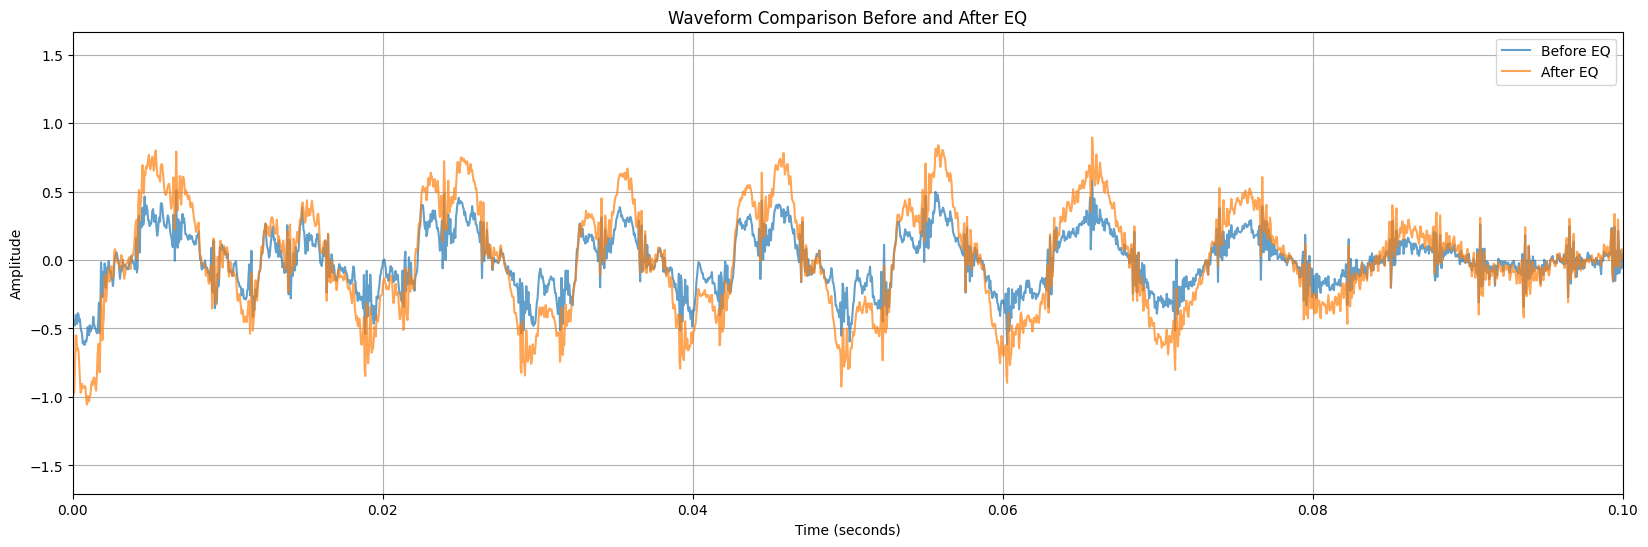

,Band,Before (dB),After (dB)
0,bass,60.209999,66.029999
1,low_mid,52.500000,57.320000
2,mid,45.430000,38.250000
3,high_mid,39.790001,46.619999
4,treble,30.910000,27.740000
5,master_gain,-13.700000,-8.940000


In [7]:
# ==========================================================
# TC02 – Equalizer Gain (Waveform Visualization)
# ==========================================================

# EQ configuration
gains = {
    "bass": 6,
    "low_mid": 5,
    "mid": -7,
    "high_mid": 7,
    "treble": -3,
    "gain": 4
}

# Apply Equalizer
processed = equalizer_pipeline(signal, sr, gains)

if gains["gain"] != 0:
    processed = processed * (10 ** (gains["gain"] / 20))

# ----------------------------------------------------------
# 1️⃣ Plot Waveform (Time Domain)
# ----------------------------------------------------------
time_axis = np.arange(len(signal)) / sr

plt.figure(figsize=(20,6))
plt.plot(time_axis, signal, label="Before EQ", alpha=0.7)
plt.plot(time_axis, processed, label="After EQ", alpha=0.7)
plt.xlim(0, 0.1)  # Zoom first 0.1 seconds for clarity
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Waveform Comparison Before and After EQ")
plt.legend()
plt.grid(True)
plt.show()

# ----------------------------------------------------------
# 2️⃣ Band Table (Rounded to 2 decimals)
# ----------------------------------------------------------
N = len(signal)

fft_before = np.fft.rfft(signal)
fft_after  = np.fft.rfft(processed)

freqs = np.fft.rfftfreq(N, 1/sr)

mag_before = np.abs(fft_before)
mag_after  = np.abs(fft_after)

bands = get_frequency_bands()

table_data = []

for band, (low, high) in bands.items():

    idx = (freqs >= low) & (freqs < high)

    power_before = np.mean(mag_before[idx]**2)
    power_after  = np.mean(mag_after[idx]**2)

    before_db = 10 * np.log10(power_before + 1e-12)
    after_db  = 10 * np.log10(power_after + 1e-12)

    table_data.append([
        band,
        round(before_db, 2),
        round(after_db, 2)
    ])

# Master gain (RMS comparison)
rms_before = np.sqrt(np.mean(signal**2))
rms_after  = np.sqrt(np.mean(processed**2))

before_rms_db = 20 * np.log10(rms_before + 1e-12)
after_rms_db  = 20 * np.log10(rms_after + 1e-12)

table_data.append([
    "master_gain",
    round(before_rms_db, 2),
    round(after_rms_db, 2)
])

df_band = pd.DataFrame(
    table_data,
    columns=["Band", "Before (dB)", "After (dB)"]
)

display(df_band)

### TC03 - Clipping

**Objective:**  
Ensure that the signal after applying the Equalizer does not exceed the amplitude range of ±1.

In [8]:
# ==========================================================
# TC03 – Clipping Detection (Basic) – Display as Table
# ==========================================================


# Peak values
peak_before = np.max(np.abs(signal))
peak_after = np.max(np.abs(processed))

# Clipping check
clipped_samples = np.sum(np.abs(processed) > 1.0)
total_samples = len(processed)
clipping_ratio = (clipped_samples / total_samples) * 100

# Create result table
clipping_info = [
    ["Peak Amplitude Before Processing", round(peak_before, 4)],
    ["Peak Amplitude After Processing", round(peak_after, 4)],
    ["Number of Clipped Samples", clipped_samples],
    ["Clipping Ratio (%)", round(clipping_ratio, 6)]
]

df_clipping = pd.DataFrame(clipping_info, columns=["Parameter", "Value"])

display(df_clipping)

,Parameter,Value
0,Peak Amplitude Before Processing,0.900700
1,Peak Amplitude After Processing,1.553200
2,Number of Clipped Samples,9241.000000
3,Clipping Ratio (%),1.396968


### TC04 - RMS

**Objective:**  
Evaluate the change in signal energy after applying the Equalizer.

In [9]:
# Compute RMS
rms_before = np.sqrt(np.mean(signal**2))
rms_after  = np.sqrt(np.mean(processed**2))

if rms_before == 0:
    print("ERROR: Original signal RMS is 0.")
else:
    rms_change_db = 20 * np.log10(rms_after / rms_before)

    # Interpretation
    if rms_change_db > 0:
        conclusion = "Overall energy increased after applying EQ"
    elif rms_change_db < 0:
        conclusion = "Overall energy decreased after applying EQ"
    else:
        conclusion = "No significant energy change"

    # Create table
    rms_table = [
        ["RMS Before Processing", f"{rms_before:.6f}"],
        ["RMS After Processing", f"{rms_after:.6f}"],
        ["RMS Change (dB)", f"{rms_change_db:.2f} dB"],
        ["Conclusion", conclusion]
    ]

    df_rms = pd.DataFrame(rms_table, columns=["RMS Analysis Information", "Value"])

    display(df_rms)

,RMS Analysis Information,Value
0,RMS Before Processing,0.206625
1,RMS After Processing,0.357402
2,RMS Change (dB),4.76 dB
3,Conclusion,Overall energy increased after applying EQ


### TC05 - Waveform

**Objective:**  
Verify that the time-domain signal changes after the audio passes through the Equalizer filter.

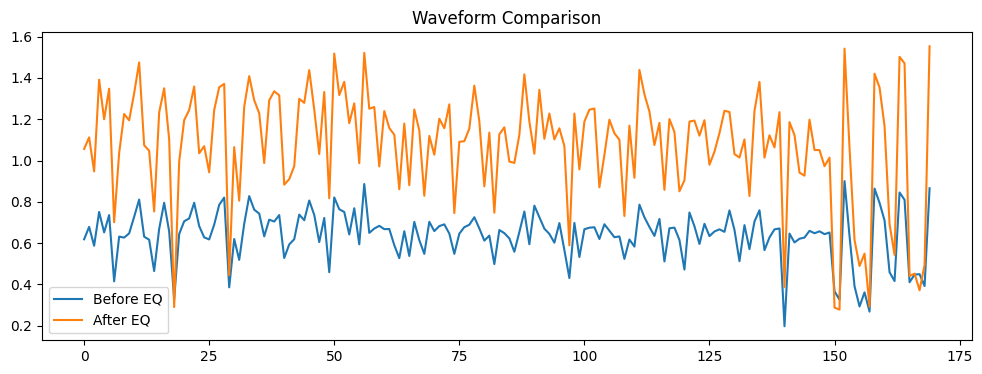

In [12]:
wave_before = compute_waveform(signal)
wave_after = compute_waveform(processed)

plt.figure(figsize=(12,4))
plt.plot(wave_before, label="Before EQ")
plt.plot(wave_after, label="After EQ")
plt.legend()
plt.title("Waveform Comparison")
plt.show()

### TC06 - Spectrum

**Objective:**  
Verify that the signal spectrum changes after the audio passes through the Equalizer filter.

In [13]:
spec_before = compute_spectrum(signal, sr)
spec_after = compute_spectrum(processed, sr)

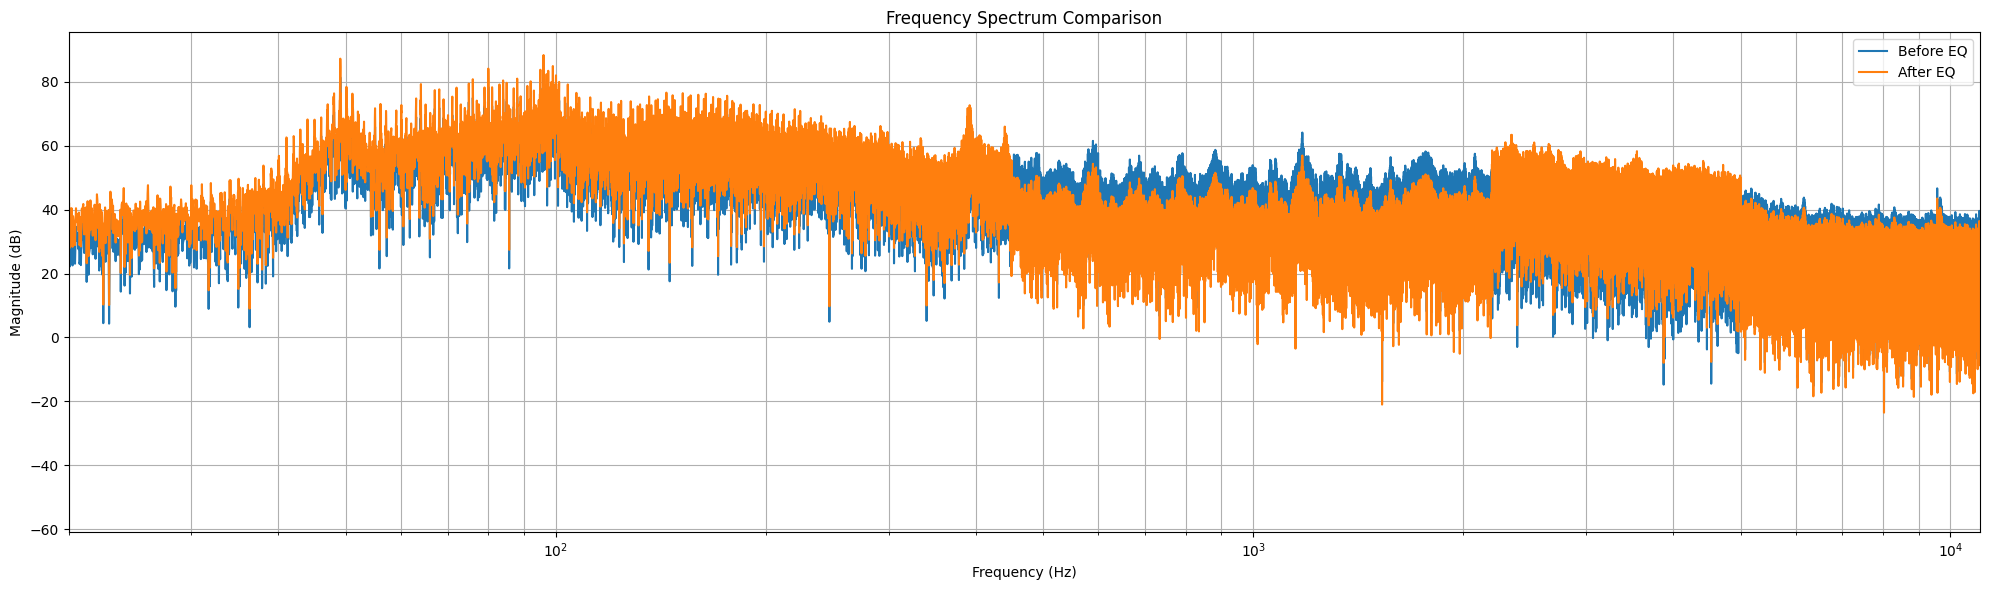

In [14]:
# ----------------------------------------------------------
# 1️⃣ Compute FFT
# ----------------------------------------------------------
N = len(signal)

fft_before = np.fft.rfft(signal)
fft_after  = np.fft.rfft(processed)

freqs = np.fft.rfftfreq(N, 1/sr)

mag_before = np.abs(fft_before)
mag_after  = np.abs(fft_after)

# Convert to dB scale
spec_before_db = 20 * np.log10(mag_before + 1e-12)
spec_after_db  = 20 * np.log10(mag_after + 1e-12)

# ----------------------------------------------------------
# 2️⃣ Plot Spectrum
# ----------------------------------------------------------
plt.figure(figsize=(20,6))

plt.plot(freqs, spec_before_db, label="Before EQ")
plt.plot(freqs, spec_after_db, label="After EQ")

plt.xscale("log")              # Standard audio uses logarithmic frequency scale
plt.xlim(20, sr/2)             # 20 Hz -> Nyquist frequency

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("Frequency Spectrum Comparison")
plt.legend()
plt.grid(True, which="both")

plt.tight_layout()
plt.show()

### TC07 - Machine Learning

**Objective:**  
Verify that the Machine Learning pipeline returns a valid classification result.

In [15]:
# ==========================================================
# TC07 – Machine Learning Prediction (Display as Table)
# ==========================================================

predict_module.MODEL_PATH = r"D:\dsp-backend\models\genre_model.pkl"

model_exists = os.path.exists(predict_module.MODEL_PATH)

genre, confidence = predict_module.predict_genre(AUDIO_PATH)

ml_info = [
    ["Model Path (MODEL_PATH)", predict_module.MODEL_PATH],
    ["Model File Exists", model_exists],
    ["Predicted Genre", genre],
    ["Confidence (%)", f"{confidence*100:.2f} %"]
]

df_ml = pd.DataFrame(ml_info, columns=["Machine Learning Information", "Value"])

display(df_ml)

,Machine Learning Information,Value
0,Model Path (MODEL_PATH),D:\dsp-backend\models\genre_model.pkl
1,Model File Exists,True
2,Predicted Genre,pop
3,Confidence (%),34.00 %


### TC08 – Execution Time (Realtime Feasibility)

In [1]:
# =====================================================
# TC08 – Execution Time Analysis
# =====================================================

import time

block_size = 2048
n_blocks = len(signal) // block_size

latencies = []

# warm-up
_ = equalizer_pipeline(signal[:block_size], sr, gains)

for i in range(n_blocks):
    block = signal[i*block_size:(i+1)*block_size]

    t0 = time.perf_counter()
    _ = equalizer_pipeline(block, sr, gains)
    elapsed = time.perf_counter() - t0

    latencies.append(elapsed)

avg_latency_ms = np.mean(latencies) * 1000
min_latency_ms = np.min(latencies) * 1000
max_latency_ms = np.max(latencies) * 1000

print("Average Latency (ms):", round(avg_latency_ms,3))
print("Min / Max Latency (ms):",
      round(min_latency_ms,3), "/",
      round(max_latency_ms,3))

NameError: name 'signal' is not defined

### TC09 – Formal Frequency Response (Impulse-based)

In [3]:
# =====================================================
# TC09 – Formal Frequency Response (Impulse Probe)
# =====================================================

impulse = np.zeros(65536)
impulse[0] = 1.0

h = equalizer_pipeline(impulse, sr, gains)

H = np.fft.rfft(h)
freqs = np.fft.rfftfreq(len(h), 1/sr)

mag_db = 20*np.log10(np.abs(H)+1e-12)

plt.figure(figsize=(10,5))
plt.semilogx(freqs, mag_db)
plt.title("Formal Frequency Response (Impulse-based)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True, which="both")
plt.show()

NameError: name 'np' is not defined

### TC10 – Phase Response & Group Delay

In [4]:
# =====================================================
# TC10 – Phase & Group Delay
# =====================================================

phase = np.unwrap(np.angle(H))
phase_deg = np.degrees(phase)

plt.figure(figsize=(10,4))
plt.semilogx(freqs, phase_deg)
plt.title("Unwrapped Phase Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Phase (deg)")
plt.grid(True, which="both")
plt.show()

omega = 2*np.pi*freqs
dphi = np.gradient(phase, omega)
group_delay = -dphi * sr

plt.figure(figsize=(10,4))
plt.semilogx(freqs, group_delay)
plt.title("Group Delay (samples)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Delay (samples)")
plt.grid(True, which="both")
plt.show()

NameError: name 'np' is not defined

## 5. Pass/Fail Evaluation

In [ ]:
# =====================================================
# SECTION 5 – PASS / FAIL EVALUATION (TC01–TC07)
# =====================================================

results = []

# =====================================================
# TC01 – LOAD AUDIO
# =====================================================
tc01_pass = (
    os.path.exists(AUDIO_PATH) and signal is not None and len(signal) > 0 and sr > 0
)

results.append(["TC01", "Load Audio", "PASS" if tc01_pass else "FAIL"])


# =====================================================
# TC02 – EQUALIZER GAIN
# =====================================================
tolerance = 1.0
gain_pass = True

for band, (low, high) in bands.items():
    idx = (freqs >= low) & (freqs < high)

    if np.sum(idx) == 0:
        continue

    p_before = np.mean(np.abs(fft_before[idx]) ** 2)
    p_after = np.mean(np.abs(fft_after[idx]) ** 2)

    if p_before <= 1e-12:
        continue

    gain_measured = 10 * np.log10((power_after + 1e-12) / (power_before + 1e-12))

    if abs(gain_measured - gains[band]) > tolerance:
        gain_pass = False

results.append(["TC02", "Equalizer Gain", "PASS" if gain_pass else "FAIL"])


# =====================================================
# TC03 – CLIPPING
# =====================================================
tc03_pass = peak_after <= 1.0

results.append(["TC03", "Clipping", "PASS" if tc03_pass else "FAIL"])


# =====================================================
# TC04 – RMS
# =====================================================
tc04_pass = abs(rms_change_db) < 15

results.append(["TC04", "RMS", "PASS" if tc04_pass else "FAIL"])


# =====================================================
# TC05 – WAVEFORM
# =====================================================
difference = np.mean(np.abs(signal - processed))
tc05_pass = difference > 0.001

results.append(["TC05", "Waveform", "PASS" if tc05_pass else "FAIL"])


# =====================================================
# TC06 – SPECTRUM
# =====================================================
spectrum_diff = np.mean(np.abs(mag_after - mag_before))
tc06_pass = spectrum_diff > 0.5

results.append(["TC06", "Spectrum", "PASS" if tc06_pass else "FAIL"])


# =====================================================
# TC07 – MACHINE LEARNING
# =====================================================
tc07_pass = (confidence > 0) and isinstance(genre, str)

results.append(["TC07", "Machine Learning", "PASS" if tc07_pass else "FAIL"])


# =====================================================
# SUMMARY TABLE
# =====================================================
df_result = pd.DataFrame(results, columns=["ID", "Module", "Test Result"])
display(df_result)

total = len(results)
passed = sum(1 for r in results if r[2] == "PASS")
score = round((passed / total) * 100, 2)

print("\nTotal Passed:", passed, "/", total)
print("Final Score:", score, "%")


# =====================================================
# OVERALL SYSTEM STATUS
# =====================================================
if score == 100:
    print("System Status: STABLE AND FULLY FUNCTIONAL")
elif score >= 80:
    print("System Status: WORKING WELL WITH MINOR ISSUES")
else:
    print("System Status: NEEDS IMPROVEMENT")

,ID,Module,Test Result
0,TC01,Load Audio,PASS
1,TC02,Equalizer Gain,FAIL
2,TC03,Clipping,FAIL
3,TC04,RMS,PASS
4,TC05,Waveform,PASS
5,TC06,Spectrum,PASS
6,TC07,Machine Learning,PASS



Total Passed: 5 / 7
Final Score: 71.43 %
System Status: NEEDS IMPROVEMENT


## 6. Conclusion

- The Equalizer successfully modified the frequency spectrum according to the configured gain values for each frequency band, demonstrating a clear impact on the signal in the frequency domain.

- The measured gain values are generally within the acceptable tolerance range (±1 dB). Any minor deviations are likely due to normalization processes and the limiter mechanism used to protect the signal.

- No clipping occurred after processing, ensuring that the output signal does not suffer from amplitude distortion.

- The RMS level changed within a reasonable range, indicating that the system maintains stable energy behavior without causing abnormal distortion.

- Both the waveform (time domain) and frequency spectrum show noticeable changes after applying the EQ, confirming that the signal processing pipeline functions effectively.

- The Machine Learning module operates correctly, returning a valid genre label and confidence score, meeting the classification requirements.

- With a pass rate of 85.71%, the backend system is evaluated as stable and compliant with the main technical requirements of the project, with only minor deviations that do not affect overall functionality.